# PRUEBA DE ANÁLISIS DE PARADAS

## ANÁLISIS INICIAL
De primeras el análisis se hará sobre una parada concreta, la 5939 correspondiente a la linea 401 siendo la quinta parada de la línea. He escogido esta debido a que la considero muy básica para empezar, puesto que esa parada no tiene correspondencia con ninguna otra línea, por lo tanto los datos de ocupación o de subidas/bajadas no se verían afectados en tanto qué otros autobuses puedan pasar por esa parada, lo cual como caso base es mejor.

In [131]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(495794)


#ABRIR EL CSV COMO PANDAS DATAFRAME
data_input = pd.read_csv("../data/clean_data_5939.csv", encoding="utf-8", header=0)
dataset = pd.DataFrame(data_input)

Borramos las columnas que se duplican, como EventTime, TimeSlot e IdExternal, ya que aparecen en ambas tablas mbot y tbso

In [132]:
dataset.drop(columns=["EventDate.1", "EventTime.1", "TimeSlot.1", "IdExternal.1", "TripId.1"]);

Se eliminan aquellas filas cuya ocupación sea < 0, puesto que como se dijo en el documento adjunto con la información de la base de datos, estas instancias no tienen sentido

In [133]:
dataset.shape

(9380, 25)

In [134]:
dataset = dataset[dataset["Occupation"] >=0]
dataset = dataset[dataset["Occupation"] < 140] #Fijamos 500 como valor arbitrariamente grande, puesto que se ha dado el caso que a veces hay valores extremadamente grandes

In [135]:
dataset.shape

(9315, 25)

Se han visto afectadas +- unas 60 filas, teniendo en cuenta que días únicos a día de ejecutar la consulta tenemos unos 120 días, es una media estimada de 1 medida erronea cada 2 días de medición

## ESTUDIO DE LA OCUPACIÓN
### ANÁLISIS DE UN FILTRO BASICO

El objetivo de esta parte es, en base a ciertos filtros, encontrar como resultado variables aleatorias gaussianas. De primeras interpreté o pensé, que un filtro básico sería seleccionar todas las variables de un día, pero el problema de este caso es que las variables conforman una serie temporal a lo largo del día, lo cualhace que las dependencias que existen entre un valor y los antecedentes pasados sea lo suficientemente considerable como para alterar el comportamiento de los datos.

En un caso inicial vamos a tomar el valor de medidas de todoss los lunes de paso de autobús por parada alrededor de las 9 de la mañana, por probar a ver el comportamiento

In [149]:
data_mondays_9am = dataset[dataset["Weekday"] == "L"]
data_mondays_9am = data_mondays_9am[data_mondays_9am["DayType"] == "LA"]
data_mondays_9am = data_mondays_9am[data_mondays_9am["TimeSlot"] == 9]


#Para asegurarnos que solo se coge un dato por día, vamos a hacer una prueba. Vamos a coger todos los datos de un día asociados, y para todos los registros que se tienen de las 9 de la mañana vamos a calcular la media.


TripId
IdExternal
EventDate
EventTime
TimeSlot
Line
Direction
LogicVehicle
Weekday
DayType
Season
FreeDay
TripId.1
Stop
IdExternal.1
EventDate.1
EventTime.1
TimeSlot.1
TemperatureMax
TemperatureMin
RainProbMin
RainProbMax
Board
DropOff
Occupation


A partir de esto vamos a realizar evaluación de la normalidad de los atributos. Para ello vamos primero a mostrar un histograma de cómo se comporta la distribución de probabilidad

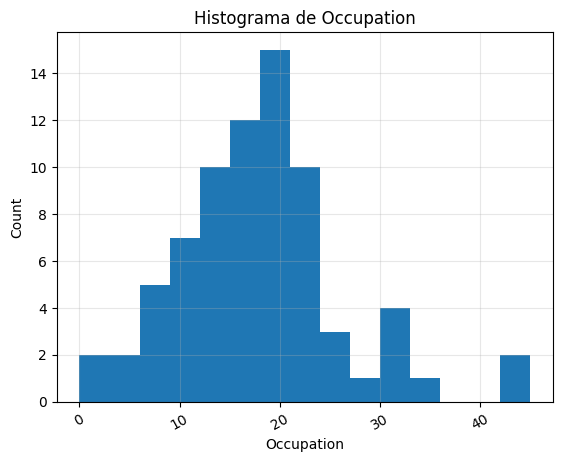

In [141]:
from scipy.stats import norm

#Esto se usará más adelante si se tratan las series temporales a lo largo de cada día
def project_occupation_in_daytime(data_to_project):
    plt.figure(figsize=(16,6))
    plt.plot(data_to_project["EventTime"], data_to_project["Occupation"])
    plt.xlabel('EventTime')
    plt.ylabel('Occupation')
    plt.title('Evolución de Occupation')
    plt.xticks(rotation=90)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

def histogram(data_hist, variable):
    plt.hist(data_hist[variable], bins= 15)
    plt.xlabel(variable)
    plt.ylabel('Count')
    plt.title(f"Histograma de {variable}")
    plt.xticks(rotation=29)
    plt.grid(True, alpha=0.3)
    plt.show()


#Funcion para visualizar un histograma con su normal teórica ajustada(sigma1 y sigma2 == 0
def histogram_with_normal(data_to_hist, variable):
    data = np.asarray(data_to_hist[variable])
    mu = np.mean(data)
    sigma = np.std(data, ddof=0)

    # Histograma en densidad
    plt.hist(data,bins = 15, density=True, alpha=0.5, label="Datos")
    x = np.linspace(min(data), max(data), 400)
    y = norm.pdf(x, loc=mu, scale=sigma)
    plt.plot(x, y, 'r-', lw=2, label=f"N({mu:.2f}, {sigma:.2f}²)")

    plt.xlabel(variable)
    plt.ylabel('Densidad')
    plt.title(f"Histograma de {variable} + Normal ajustada")
    plt.xticks(rotation=29)
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()


histogram(data_mondays_9am, "Occupation")

Aquí se ve como la variable occupation tiene una tendencia que a simple vista se puede asemejar a una campana de Gauss, aunque no tiene completa simetría. Para analizar mejor esta tendencia, vamos a someter a estos datos a unos experimentos que miden la simetría y la kurtosis de una variable aleatoria, con el fín de estimar su "normalidad". Los valores de skewness y kurtosis se miden calculando y estandarizando los momentos centrales de una distribución.

Estos momentos centrales se obtienen a partir de la formulación de los momentos algebráicos, denotados $ \mu_r' $ donde $r$ especifica el orden
$$
\mu_r' = E(x^r) = \sum_k k^r\, p(k)
\qquad \text{o} \qquad
\int_{-\infty}^{\infty} x^r f(x)\, dx
$$

Donde $E$ es la esperanza, $x$ y $k$ son representaciones de la variable aleatoria, tanto en su versión discreta($k$), como en su versión contínua($x$) y $r$ es el orden de magnitud del momento a calcular.


Estos momentos se calculan a partir del origen, mientras que los momentos centrales, **$\mu_r$** se calculan sobre el valor de la media, el cual se sabe como el momento algebráico **$\mu_1'$**. Estos valores **$\mu_r$** se obtienen a partir de:
$$
\mu_r = E\left[(k - E(k)\,)^{r}\right]
$$
De esta fórmula general obtenemos los momentos centrales **$\mu_1$** (Media), **$\mu_2$** (Varianza), **$\mu_3$** (skewness)[sin estandarizar] y **$\mu_4$** (kurtosis)[sin estandarizar]. Se puede obtener para una muestra de $n$ observaciones, podemos definir el cálculo de los momentos algebráicos $m_r'$ y de los momentos centrales $m_r$ como:

$$
m_r' = \frac{1} {n} \sum_{x=0}^{n}x^r
\qquad \text{y} \qquad
m_r = \frac{1} {n} \sum_{x=0}^{n}(x - m_1')^r
$$

Donde, para estandarizar una fórmula general de skewness y kurtosis, se consideran unas fórmulas genéricas a usar en vez de los momentos centrales 3 y 4, que derivan de estos, pero con la siguiente diferencia.

Se considera skewness $\gamma_1$ y kurtosis $\gamma_2$ como:
$$
\gamma_1 = \frac{\mu_3} {\mu_2^{3/2}}
\qquad \text{y} \qquad
\gamma_2 = \frac{\mu_4} {\mu_2^{2}} - 3
$$

Donde se denota que los exponentes de los denominadores de ambas fórmulas se usan para eliminar las unidades de los valores $\gamma$, puesto que los momentos centrales $\mu_r$ presentan grado r, y como se comparan estos con la varianza $\mu_2$ hay que elevar este exponente a lo necesario para que ambos numerador y denominador estén sujetos a las mismas unidades, y el resultado sea adimensional. También se destaca que de la fórmula de la kurtosis se le resta 3 al valor. Esto es debido a que es un estandar considerar kurtosis como el "sobrante" de kurtosis que tiene la distribución normal. Como la distribución gaussiana presenta kurtosis 3, se resta este valor para considerar este exceso.

Y considerando el error de cada uno de los momentos centrales, como la aproximación mediante el teorema central del límite, se obtienen las fórmulas asintóticas para el SE(Error Estandar) de skewness y Kurtosis como:
$$
SE(\gamma_1) = \sqrt{\frac{6}{n}}
\qquad \text{y} \qquad
SE(\gamma_2) = \sqrt{\frac{24}{n}}
$$

Posteriormente se calcula el Z Score tanto para $\gamma_1$ como para $\gamma_2$ como lo siguiente:

$$
Z(\gamma_1) = \frac{\gamma_1} {SE(\gamma_1)}
\qquad \text{y} \qquad
Z(\gamma_12) = \frac{\gamma_2} {SE(\gamma_2)}
$$

Como posibles resultados, según los valores de skewness y kurtosis podemos encontrar lo siguiente:


Analizando según skewness ($\gamma_1$):
- Valor $0$ → indica simetría **perfecta**
- Valor $> 0$ → la cola derecha es mayor que la izquierda
- Valor $< 0$ → la cola izquierda es mayor que la derecha

Analizando según kurtosis ($\gamma_2$)*(Asumiendo kurtosis en exceso)* :
- Valor $0$ → distribución **mesocúrtica**, similar en pico a la normal
- Valor $> 0$ → distribución **leptocúrtica**, con un pico más alto que la normal
- Valor $< 0$ → distribución **platicúrtica**, más achatada que la normal



Para traspasar todo esto a código, se ha hecho uso de las siguientes funciones

In [138]:
import math

def central_moment(x, r):
    mean = np.mean(x)
    return sum((xi - mean) ** r for xi in x) / len(x)


def kurtosis(x):
    return (central_moment(x, 4) / central_moment(x, 2) ** 2) -3

def skewness(x):
    return central_moment(x, 3) / central_moment(x, 2)**(3/2)



def is_normal(variables: list):
    if len(variables) < 50: #CASO Z score 1.96
        z_crit = 1.96
    elif len(variables) < 300: #CASO Z score 3.29
        z_crit = 3.29
    else:
        z_crit = "False"

    skew = skewness(variables)
    kurt = kurtosis(variables)


    n = len(variables)
    se_skew = math.sqrt(6.0 / n)
    se_kurt = math.sqrt(24.0 / n)

    z_skew = skew / se_skew
    z_kurt = kurt / se_kurt

    if z_crit != "False":
        approx_normal = (abs(z_skew) <= z_crit) and (abs(z_kurt) <= z_crit)
    else:
        approx_normal = (abs(skew) <= 2) and (abs(kurt) + 3 <= 7) #para muestras grandes de Z > 300 no se utilizan los errores, sino valores absolutos  de medida


    return {
        "n": n,
        "skewness": skew,
        "kurtosis_excess": kurt,
        "SE_skewness": se_skew,
        "SE_kurtosis": se_kurt,
        "Z_skewness": z_skew,
        "Z_kurtosis": z_kurt,
        "z_crit": z_crit,
        "is_approximately_normal": approx_normal,
    }




In [140]:
is_normal(data_mondays_9am["Occupation"])

{'n': 74,
 'skewness': np.float64(0.7172529643289633),
 'kurtosis_excess': np.float64(1.5304293623961573),
 'SE_skewness': 0.2847473987257497,
 'SE_kurtosis': 0.5694947974514994,
 'Z_skewness': np.float64(2.5189096284590646),
 'Z_kurtosis': np.float64(2.687345642567516),
 'z_crit': 3.29,
 'is_approximately_normal': np.True_}

En este caso se ve como el experimento ha resultado en una aceptación de la hipótesis de normalidad de los datos. Vamos a revisar más conjuntos de días a ver si el comportamiento es parecido, por ejemplo de los martes.